
# Лабораторная работа 1
## (Квази)линейные методы классификации

**ФИО:** Елисеев Андрей Дмитриевич

**Группа:** 24213  

**Дата:** 04.10.2026

### Цель

Исследовать несколько (квази)линейных методов классификации на данных Iris, визуально сравнить разделяющие поверхности и самостоятельно реализовать квадратичный дискриминант.

### Что должно быть в итоговом notebook

- рабочий код;
- все требуемые графики;
- короткие выводы после каждого содержательного пункта;
- notebook запускается сверху вниз через **Run All**;
- в конце — общий вывод по работе.


## 0. Импорт библиотек

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

from itertools import combinations

from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score



# 1. Исследование данных Iris

1. Загрузите таблицу Iris.
2. Поместите данные в `pandas.DataFrame`.
3. Вычислите корреляции:
   - на всей таблице;
   - отдельно по классам (`groupby`).
4. Визуализируйте распределения классов на всех парах переменных.
5. Сделайте краткие выводы:
   - какие признаки коррелируют сильнее всего;
   - отличаются ли корреляции внутри классов от общей картины;
   - какие классы проще/сложнее разделить визуально.


In [14]:

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["target"] = iris.target
df["class"] = df["target"].map(dict(enumerate(iris.target_names)))

display(df.head())

features = list(iris.feature_names)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,class
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [15]:
df[features].corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


In [16]:
df.groupby("class")[features].corr()

sepal length (cm)  sepal width (cm)  \
class                                                               
setosa     sepal length (cm)           1.000000          0.742547   
           sepal width (cm)            0.742547          1.000000   
           petal length (cm)           0.267176          0.177700   
           petal width (cm)            0.278098          0.232752   
versicolor sepal length (cm)           1.000000          0.525911   
           sepal width (cm)            0.525911          1.000000   
           petal length (cm)           0.754049          0.560522   
           petal width (cm)            0.546461          0.663999   
virginica  sepal length (cm)           1.000000          0.457228   
           sepal width (cm)            0.457228          1.000000   
           petal length (cm)           0.864225          0.401045   
           petal width (cm)            0.281108          0.537728   

                              petal length (cm)  petal width (cm)  
class                                                              
setosa     sepal length (cm)           0.267176          0.278098  
           sepal width (cm)            0.177700          0.232752  
           petal length (cm)           1.000000          0.331630  
           petal width (cm)            0.331630          1.000000  
versicolor sepal length (cm)           0.754049          0.546461  
           sepal width (cm)            0.560522          0.663999  
           petal length (cm)           1.000000          0.786668  
           petal width (cm)            0.786668          1.000000  
virginica  sepal length (cm)           0.864225          0.281108  
           sepal width (cm)            0.401045          0.537728  
           petal length (cm)           1.000000          0.322108  
           petal width (cm)            0.322108          1.000000

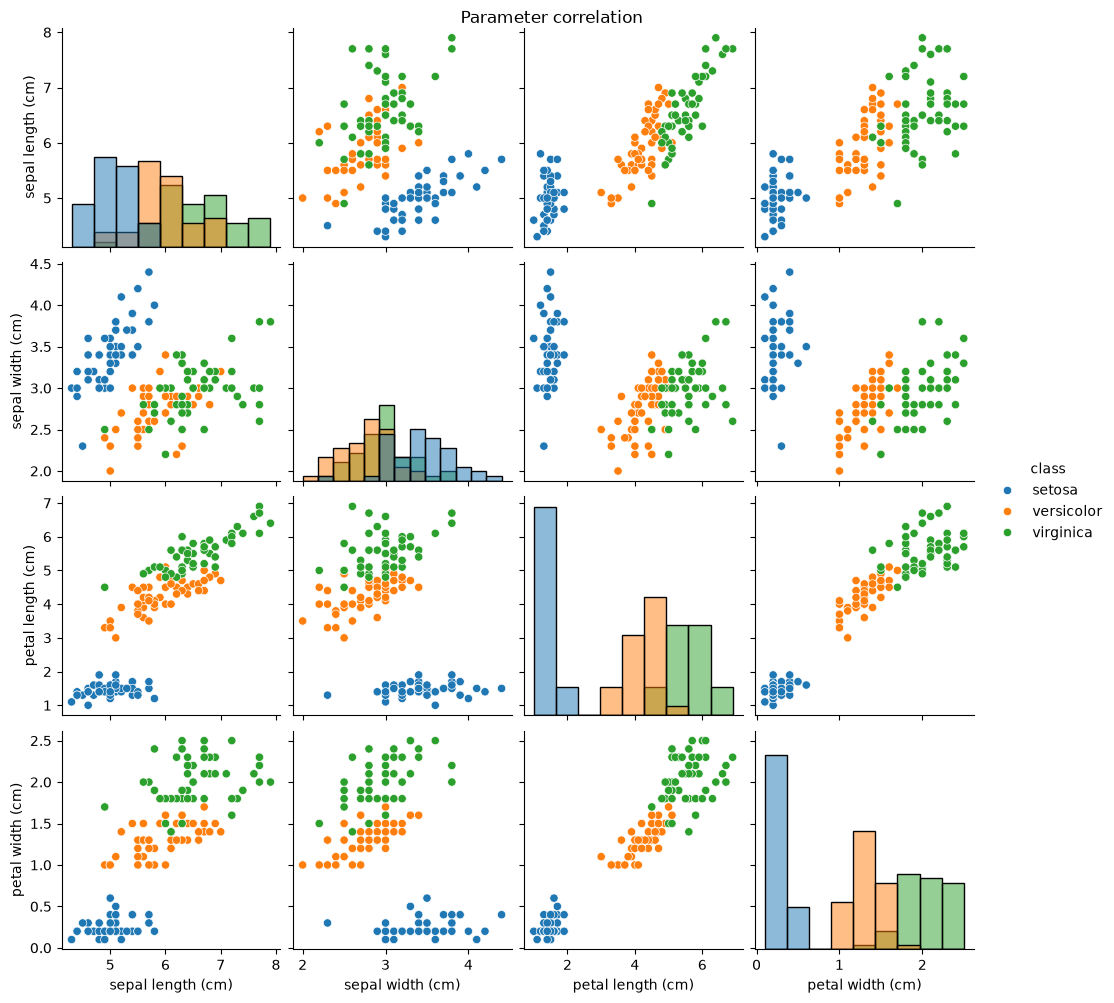

In [17]:

sns.pairplot(
    df,
    vars=features,
    hue="class",
    diag_kind="hist"
).fig.suptitle("Parameter correlation", y=1) 
plt.show()



### Выводы по пункту 1

По всему датасету больше всего коррелируют длина и ширина лепестка. Также высокая связь длины чашелистика с длиной лепестка.

По отдельности длина и ширина лепестка сильно коррелируют только в группе versicolor. Также в группе setosa слабо коррелируют лина лепестка и чашелистика.

Визуально класс setosa легче разделить с другими двумя. Классы versicolor и virginica разделить сложнее.



# 2. Сравнение методов на двух признаках

Выберите **две переменные**.

Постройте и визуализируйте решения методами:

- Linear Discriminant Analysis (LDA);
- Quadratic Discriminant Analysis (QDA);
- Logistic Regression;
- SVM с линейным ядром;
- SVM с полиномиальным ядром степени 2.

Для каждого метода покажите разделяющую поверхность/кривую.

> На этом этапе используйте все классы Iris, если ваш код поддерживает multiclass.  
> В следующих пунктах можно оставить два наименее разделимых класса.


In [18]:

feature_idx = [0, 2]

X2 = iris.data[:, feature_idx]
y_all = iris.target

print("Selected features:", [iris.feature_names[i] for i in feature_idx])


Selected features: ['sepal length (cm)', 'petal length (cm)']


In [19]:

# Вспомогательная функция визуализации.
# Можно использовать её без изменений.

def plot_decision_regions(model, X, y, title, feature_names=None, resolution=300):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.25)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", s=40)

    if feature_names is not None:
        plt.xlabel(feature_names[0])
        plt.ylabel(feature_names[1])

    plt.title(title)
    plt.show()


LDA train accuracy: 0.9666666666666667


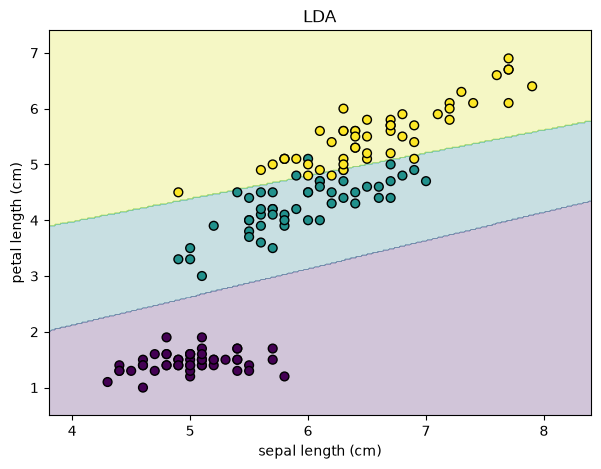

QDA train accuracy: 0.96


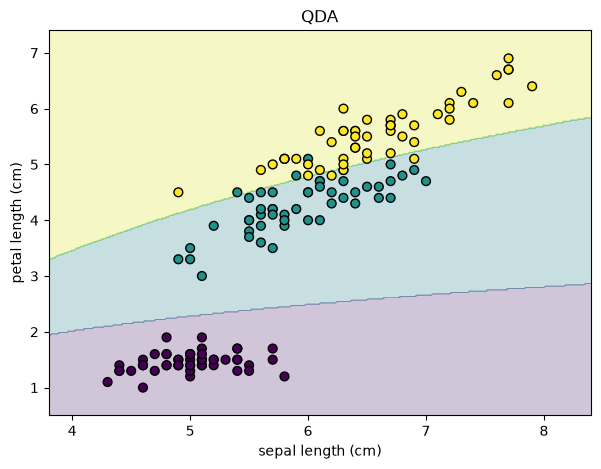

Logistic Regression train accuracy: 0.96


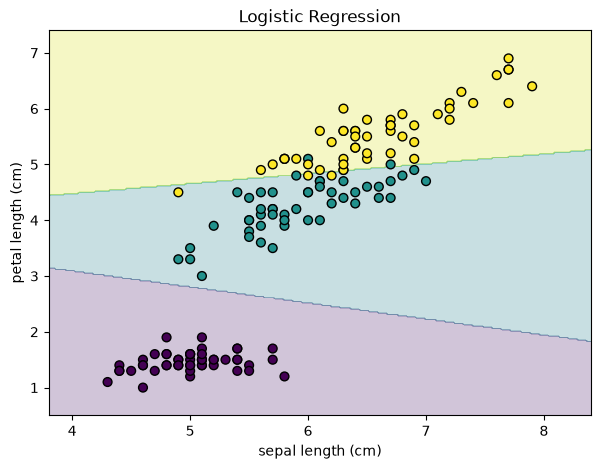

Linear SVM train accuracy: 0.9533333333333334


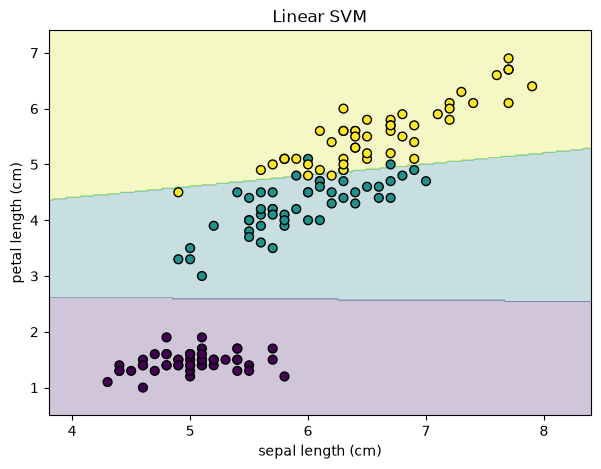

Polynomial SVM degree=2 train accuracy: 0.9533333333333334


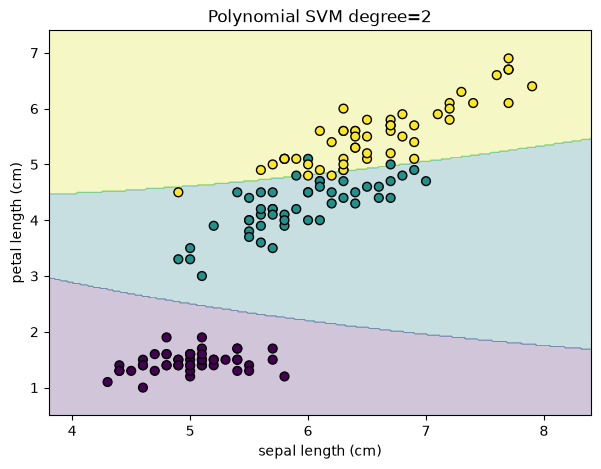

In [20]:

models = {
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis(),
    "Logistic Regression": LogisticRegression(),
    "Linear SVM": SVC(kernel="linear"),
    "Polynomial SVM degree=2": SVC(kernel="poly", degree=2),
}

for model in models.values():
    model.fit(X2, y_all)

for name, model in models.items():
    print(f"{name} train accuracy:", model.score(X2, y_all))
    plot_decision_regions(model, X2, y_all, name, [iris.feature_names[i] for i in feature_idx])



### Вопросы для выводов по пункту 2

- Какие методы дали линейную границу?
    - линейную границу дали LDA, Logisitic regression, SVM с линейным ядром
- Какие — нелинейную?
    - нелинейную границу дали QDA, SVM с квадратичным ядром
- Насколько сильно отличаются границы при похожей accuracy?
    - train accuracy везде почти одинаковый, границы очень похожие
- Почему train accuracy нельзя считать честной оценкой качества на новых данных?
    - потому что это оценка использует те же данные, что использовались для обучения; модель может показывать хорошие результаты только на данных для обучения, но не на новых данных; для лучшей оценки нужна отдельная выборка, которой не было в тренировочных данных


# 3. LDA на всех признаках

Можно оставить только **два наименее разделимых класса**.

1. Обучите LDA на всех четырёх признаках.
2. Получите ответы алгоритма на обучающей выборке.
3. Во всех двумерных подпространствах визуализируйте:
   - истинный класс объекта;
   - ответ алгоритма.

Рекомендуемый способ:
- цвет = предсказанный класс;
- форма маркера или обводка = истинный класс / правильность ответа.


In [21]:
mask = iris.target != 0
X = iris.data[mask]
y = iris.target[mask]

lda = LinearDiscriminantAnalysis().fit(X, y)


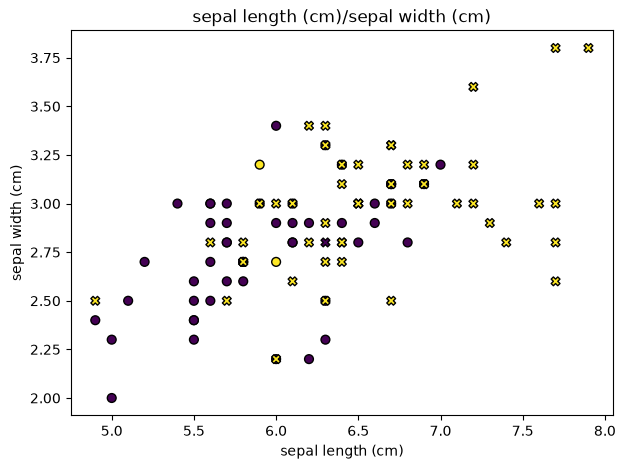

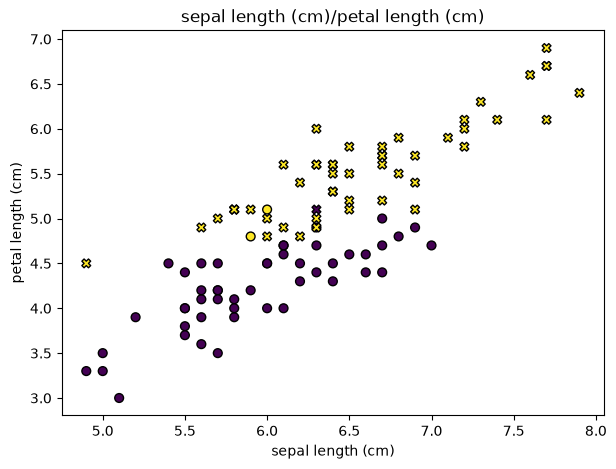

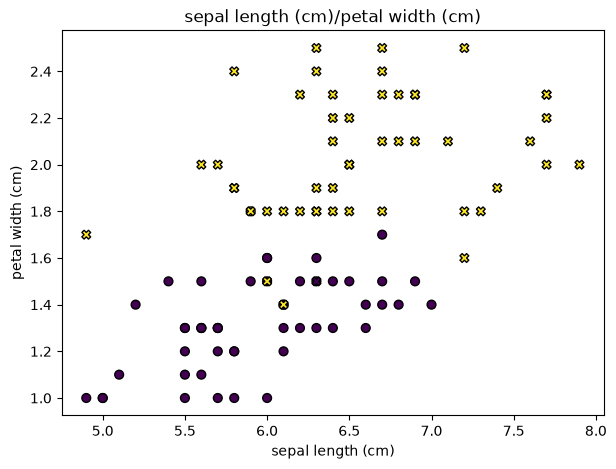

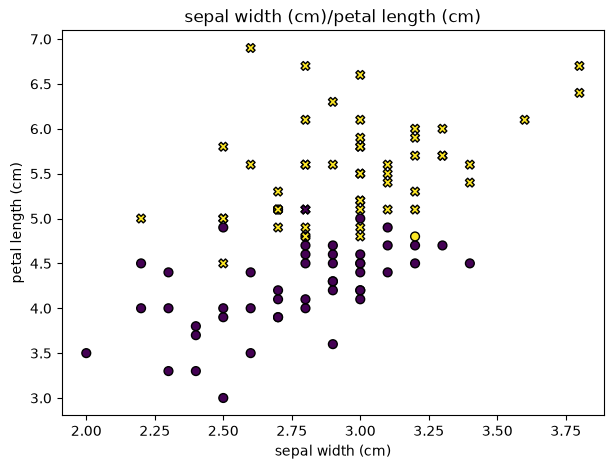

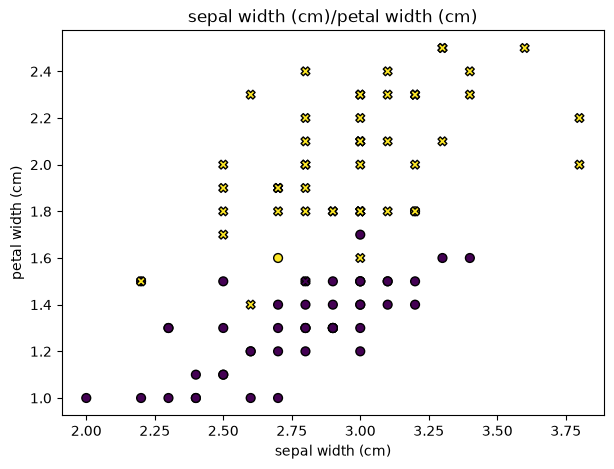

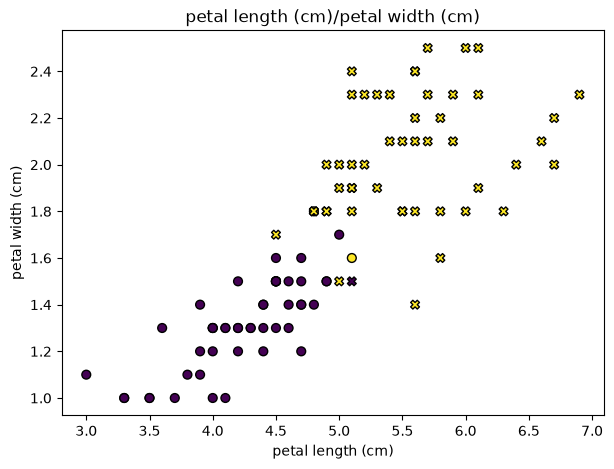

In [22]:
def plot_feature_pair(model, X, y, feat_pair, title, feature_names=None, resolution=300):
    feat_x, feat_y = feat_pair
    x_min, x_max = X[:, feat_x].min() - 0.5, X[:, feat_x].max() + 0.5
    y_min, y_max = X[:, feat_y].min() - 0.5, X[:, feat_y].max() + 0.5
    
    plt.figure(figsize=(7, 5))

    prediction = model.predict(X)
    for i in range(3):
        mask = y == i
        plt.scatter(X[:, feat_x][mask], X[:, feat_y][mask], c=prediction[mask], marker="soX"[i], edgecolors="k", s=40)

    if feature_names is not None:
        plt.xlabel(feature_names[feat_x])
        plt.ylabel(feature_names[feat_y])

    plt.title(title)
    plt.show()

for feat_pair in combinations(range(4), 2):
    feat_x, feat_y = feat_pair
    title = f"{iris.feature_names[feat_x]}/{iris.feature_names[feat_y]}"
    plot_feature_pair(lda, X, y, feat_pair, title, iris.feature_names)


### Выводы по пункту 3

- На каких проекциях ошибки видны лучше?
    - ошибки лучше всего видны на первых двух проекциях
- Может ли объект выглядеть «неправильно» на 2D-проекции, но быть правильно классифицированным в 4D? Почему?
    - нет, это одни и те же объекты, просто показанные с "разных ракурсов"; если цвет соответствует форме, то он соотвествует с любого "ракурса".



# 4. Самостоятельная реализация QDA

Используйте две переменные из пункта 2 и два наименее разделимых класса.

Для каждого класса $k$ оцените:

- вектор средних $\mu_k$;
- ковариационную матрицу $\Sigma_k$;
- априорную вероятность $\pi_k$.

Используйте дискриминант:

$$
\delta_k(x)=
-\frac{1}{2}\log |\Sigma_k|
-\frac{1}{2}(x-\mu_k)^T\Sigma_k^{-1}(x-\mu_k)
+\log \pi_k.
$$

Прогноз — класс с максимальным значением $\delta_k(x)$.

**Нельзя** использовать `QuadraticDiscriminantAnalysis` внутри собственной реализации.  
Готовый sklearn-QDA можно использовать только для сравнения результата.


In [23]:
feature_idx = np.array([0, 2])
class_idx = np.array([1, 2])

X = [iris.data[iris.target == cl, :][:, feature_idx] for cl in class_idx]
y = [iris.target[iris.target == cl] for cl in class_idx]
X_all = np.vstack(tuple(X))
y_all = np.hstack(tuple(y))
N_all = X_all.size

In [24]:
params = [{
    "mu": np.mean(X[k], axis=0),
    "cov": np.cov(X[k], rowvar=False),
    "prior": X[k].shape[0] / N_all,
} for k in range(len(X))]

In [25]:
def qda_score(X, mu, cov, prior):
    X = np.transpose(X)
    log_det_cov = np.log(np.linalg.det(cov))
    cov_inv = np.linalg.inv(cov)
    diff_t = np.transpose(X - mu[:, None])
    quadratic = np.sum((diff_t @ cov_inv) * diff_t, axis=1, keepdims=True)
    log_prior = np.log(prior)
    return -0.5 * log_det_cov - 0.5 * quadratic + log_prior

In [26]:
def manual_qda_predict(X, y_map, params):
    scores = tuple(qda_score(X, param["mu"], param["cov"], param["prior"]) for param in params)
    score_matrix = np.hstack(scores)
    return y_map[np.argmax(score_matrix, axis=1, keepdims=True)]

def accuracy(X, y_map, y, params):
    hits = manual_qda_predict(X, y_map, params).ravel() == y
    return np.count_nonzero(hits) / np.size(y)
    

Manual train accuracy: 0.94


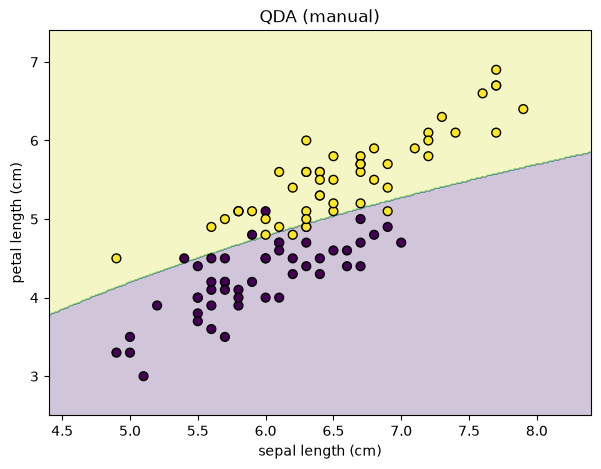

Library train accuracy: 0.94


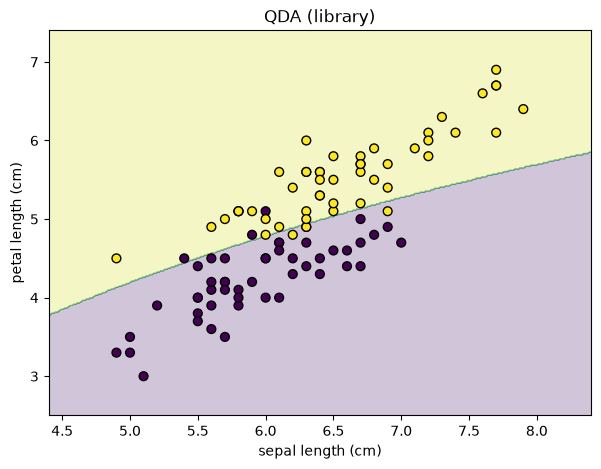

In [27]:

def plot_decision_regions_manual(params, X, y, class_idx, title, feature_names=None, resolution=300):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = manual_qda_predict(grid, class_idx, params).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.25)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", s=40)

    if feature_names is not None:
        plt.xlabel(feature_names[0])
        plt.ylabel(feature_names[1])

    plt.title(title)
    plt.show()

print("Manual train accuracy:", accuracy(X_all, class_idx, y_all, params))
plot_decision_regions_manual(params, X_all, y_all, class_idx, "QDA (manual)", [iris.feature_names[i] for i in feature_idx])

qda = QuadraticDiscriminantAnalysis().fit(X_all, y_all)
print("Library train accuracy:", qda.score(X_all, y_all))
plot_decision_regions(qda, X_all, y_all, "QDA (library)", [iris.feature_names[i] for i in feature_idx])



### Вопросы для выводов по пункту 4

- Почему QDA называется квадратичным?
    - потому что в функции дискриминанта есть слагаемое с произведениями и квадратами элементов оцениваемого вектора
- Что изменится, если ковариационные матрицы двух классов считать одинаковыми?
    - алгоритм выродится в LDA
- Почему при малой выборке QDA может оказаться менее устойчивым, чем LDA?
    - потому что больше параметров, которые нужно рассчитать, поэтому при малом объеме данных могут не успеть сойтись
- Совпало ли ваше решение со sklearn? Если нет — найдите источник различий.
    - да, получились идентичные результаты



# Итоговый вывод

Все методы дали похожие решения. У SVM с квадратичным ядром и QDA кривые границы, у остальных - прямые. У LDA границы - прямые, потому что в функции оценки координаты вектора не умножаются друг на друга. У QDA граница - кривая второго порядка, так как в функции присутствуют квадраты и произведения координат вектора. 

Iris хорошо разделяется по длине и ширине лепестка, хуже - по характеристикам чашелистика. Хорошо можно использовать длину и ширину лепестка в совокупности, также длину чашелистика и лепестка. 

При реализации QDA было важнее всего понять общий принцип метода. Есть несколько оценочных функций, которые применяются к вектору и берется вариант с лучшей оценкой.

Для честного сравнения качества методов на новых данных я бы разделил датасет на тренировочные данные и контрольную выборку. Второе бы не использовал при тренировке; только при оценке.


# Чек-лист перед защитой

- [x] Notebook запускается через **Run All**
- [x] Есть ФИО и группа
- [x] Выполнены все пункты
- [x] Все графики подписаны
- [x] Есть выводы, а не только код
- [x] Я могу объяснить разницу между LDA и QDA
- [x] Я могу объяснить, что делает `C` в SVM
- [x] Я понимаю, почему train accuracy — не честная оценка качества
- [x] Я могу изменить выбранные признаки / параметры модели прямо на защите
- [x] Я понимаю собственную реализацию QDA
